# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.fm Data Science Portfolio
*By Mark Lambert - C00192497 | [LinkedIn](https://www.linkedin.com/in/mark-lambert-27tw721921/) | [GitHub](https://github.com/lambert-27)* | [Personal Email](mailto:marklambert123@gmail.com)

*Lecturer: Ben O'Shaughnessey*

*Submission date: 27 November 2026*

*Start Date: 6th October 2026*

---

This portfolio explores my own Last.fm listening history, roughly 18,000 scrobbles collected through the Last.fm API and joined to Spotify audio features from a Hugging Face dataset

The first half of the notebook focuses on data collection and cleaning, taking the raw API response and turning it into a tidy dataframe with artist, album, track, timestamp, time of day and a loved flag

The second half uses that dataset to ask questions using Data Science models and machine learning techniques learned during Semester 1


In [19]:
import requests
import pandas as pd
import numpy as np
import lastfm_creds
import matplotlib.pyplot as plt
from datasets import load_dataset
from huggingface_hub import login
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, mean_absolute_error, silhouette_score, confusion_matrix
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
import seaborn as sns

API_KEY = lastfm_creds.API_KEY
USERNAME = lastfm_creds.USERNAME
HF_KEY = lastfm_creds.HF_KEY

In [4]:
all_tracks = []
page = 1
total_pages = 1

while page <= total_pages:
    response = requests.get('http://ws.audioscrobbler.com/2.0/', params={
        'method': 'user.getrecenttracks',
        'user': USERNAME,
        'api_key': API_KEY,
        'format': 'json',
        'limit': 200,
        'page': page
    })
    data = response.json()
    if page == 1:
        total_pages = int(data['recenttracks']['@attr']['totalPages'])
    all_tracks.extend(data['recenttracks']['track'])
    page += 1

The data's raw columns.

The ones that this portfolio will focus on are **artist, album, name and date**. ```@attr``` holds songs that are marked ```nowplaying = true```. 

As such, anything with this attribute will also be ignored later on.

In [5]:
scrobblesResponse = pd.DataFrame(all_tracks)

scrobblesResponse.columns

Index(['artist', 'streamable', 'image', 'mbid', 'album', 'name', '@attr',
       'url', 'date'],
      dtype='str')

The raw data shows that the actual readable details for each artist, album are embedded with a ```#text``` key in a dictionary, which must be extracted

In [6]:
scrobblesResponse

,artist,streamable,image,mbid,album,name,@attr,url,date
0,{'mbid': '10adbe5e-a2c0-4bf3-8249-2b4cbf6e6ca8...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",,"{'mbid': '', '#text': 'Blue Lines (2012 Mix/Ma...",Unfinished Sympathy,{'nowplaying': 'true'},https://www.last.fm/music/Massive+Attack/_/Unf...,NaN
1,{'mbid': '10adbe5e-a2c0-4bf3-8249-2b4cbf6e6ca8...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",0094d2a2-d7f1-4dbc-a534-e3d2b441ef48,"{'mbid': '', '#text': 'Blue Lines (2012 Mix/Ma...",Five Man Army - 2012 Mix/Master,NaN,https://www.last.fm/music/+noredirect/Massive+...,"{'uts': '1793640272', '#text': '02 Nov 2026, 1..."
2,{'mbid': '10adbe5e-a2c0-4bf3-8249-2b4cbf6e6ca8...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",ede2f6c9-ad54-4161-9f00-f815e55ff3d8,"{'mbid': '', '#text': 'Blue Lines (2012 Mix/Ma...",Be Thankful for What You've Got - 2012 Mix/Master,NaN,https://www.last.fm/music/+noredirect/Massive+...,"{'uts': '1793639908', '#text': '02 Nov 2026, 1..."
3,{'mbid': '10adbe5e-a2c0-4bf3-8249-2b4cbf6e6ca8...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",affc13cc-54c8-4287-ae79-83682a3a9c96,"{'mbid': '', '#text': 'Blue Lines (2012 Mix/Ma...",Blue Lines - 2012 Mix/Master,NaN,https://www.last.fm/music/+noredirect/Massive+...,"{'uts': '1793639658', '#text': '02 Nov 2026, 1..."
4,{'mbid': '10adbe5e-a2c0-4bf3-8249-2b4cbf6e6ca8...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",ea96c118-9de2-4e2a-95c3-f584fb8ebc82,"{'mbid': '', '#text': 'Blue Lines (2012 Mix/Ma...",One Love - 2012 Mix/Master,NaN,https://www.last.fm/music/+noredirect/Massive+...,"{'uts': '1793639396', '#text': '02 Nov 2026, 1..."
...,...,...,...,...,...,...,...,...,...
18738,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",362c85ba-c79b-478e-8321-0383c3ac8101,{'mbid': '0d2cb66c-3a32-4f81-b977-9231c461c34a...,Why Won't They Talk to Me?,NaN,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,"{'uts': '1763463648', '#text': '18 Nov 2025, 1..."
18739,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",6f93589f-4a47-4a9d-9274-09a0f437ad15,{'mbid': '10ac58ca-0655-4b16-a6cb-58fdc309de0a...,Over,NaN,https://www.last.fm/music/Portishead/_/Over,"{'uts': '1763463370', '#text': '18 Nov 2025, 1..."
18740,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",6da0b598-d9cf-4f62-8376-bc3181e509af,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Obsolete,NaN,https://www.last.fm/music/Tame+Impala/_/Obsolete,"{'uts': '1763462844', '#text': '18 Nov 2025, 1..."
18741,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",ad79b526-8df8-4e79-8756-0607df153e59,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Piece Of Heaven,NaN,https://www.last.fm/music/Tame+Impala/_/Piece+...,"{'uts': '1763462559', '#text': '18 Nov 2025, 1..."


Next, as per [Carlos Medina's article](https://medium.com/hemisferios/using-the-last-fm-api-to-extract-data-and-analyzing-it-with-python-part-1-ffe96f812455), first we must select the colums of interest and, as the column name is obscure I have chosen to rename it to **song**

In [7]:
scrobbles = scrobblesResponse

scrobbles = scrobbles[['artist', 'album', 'name', 'url', 'date']]
scrobbles.rename(columns={'name': 'song'}, inplace=True)
scrobbles

,artist,album,song,url,date
0,{'mbid': '10adbe5e-a2c0-4bf3-8249-2b4cbf6e6ca8...,"{'mbid': '', '#text': 'Blue Lines (2012 Mix/Ma...",Unfinished Sympathy,https://www.last.fm/music/Massive+Attack/_/Unf...,NaN
1,{'mbid': '10adbe5e-a2c0-4bf3-8249-2b4cbf6e6ca8...,"{'mbid': '', '#text': 'Blue Lines (2012 Mix/Ma...",Five Man Army - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"{'uts': '1793640272', '#text': '02 Nov 2026, 1..."
2,{'mbid': '10adbe5e-a2c0-4bf3-8249-2b4cbf6e6ca8...,"{'mbid': '', '#text': 'Blue Lines (2012 Mix/Ma...",Be Thankful for What You've Got - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"{'uts': '1793639908', '#text': '02 Nov 2026, 1..."
3,{'mbid': '10adbe5e-a2c0-4bf3-8249-2b4cbf6e6ca8...,"{'mbid': '', '#text': 'Blue Lines (2012 Mix/Ma...",Blue Lines - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"{'uts': '1793639658', '#text': '02 Nov 2026, 1..."
4,{'mbid': '10adbe5e-a2c0-4bf3-8249-2b4cbf6e6ca8...,"{'mbid': '', '#text': 'Blue Lines (2012 Mix/Ma...",One Love - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"{'uts': '1793639396', '#text': '02 Nov 2026, 1..."
...,...,...,...,...,...
18738,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,{'mbid': '0d2cb66c-3a32-4f81-b977-9231c461c34a...,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,"{'uts': '1763463648', '#text': '18 Nov 2025, 1..."
18739,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,{'mbid': '10ac58ca-0655-4b16-a6cb-58fdc309de0a...,Over,https://www.last.fm/music/Portishead/_/Over,"{'uts': '1763463370', '#text': '18 Nov 2025, 1..."
18740,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,"{'uts': '1763462844', '#text': '18 Nov 2025, 1..."
18741,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,"{'uts': '1763462559', '#text': '18 Nov 2025, 1..."


Next, convert the ```artist``` ```album``` and ```date``` to strings

In [8]:
scrobbles['artist'] = scrobbles['artist'].astype(str)
scrobbles['album'] = scrobbles['album'].astype(str)
scrobbles['date'] = scrobbles['date'].astype(str)

Extract the embedded ```#text``` attribute from each of the ```artist, album``` and ```date``` fields

In [9]:
scrobbles[['mbid2','artist']]=scrobbles['artist'].str.split("#text':", n = 1, expand = True)
scrobbles= scrobbles.drop('mbid2', axis=1)
scrobbles[['mbid3','album']]=scrobbles['album'].str.split("#text':", n = 1, expand = True)
scrobbles= scrobbles.drop('mbid3', axis=1)
scrobbles[['uts','date']]=scrobbles['date'].str.split("#text':", n = 1, expand = True)
scrobbles.head()

,artist,album,song,url,date,uts
0,'Massive Attack'},'Blue Lines (2012 Mix/Master)'},Unfinished Sympathy,https://www.last.fm/music/Massive+Attack/_/Unf...,NaN,NaN
1,'Massive Attack'},'Blue Lines (2012 Mix/Master)'},Five Man Army - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"'02 Nov 2026, 17:24'}","{'uts': '1793640272', '"
2,'Massive Attack'},'Blue Lines (2012 Mix/Master)'},Be Thankful for What You've Got - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"'02 Nov 2026, 17:18'}","{'uts': '1793639908', '"
3,'Massive Attack'},'Blue Lines (2012 Mix/Master)'},Blue Lines - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"'02 Nov 2026, 17:14'}","{'uts': '1793639658', '"
4,'Massive Attack'},'Blue Lines (2012 Mix/Master)'},One Love - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"'02 Nov 2026, 17:09'}","{'uts': '1793639396', '"


Removing the ```}``` and ```'``` characters from the ```artist and album``` entries

In [10]:
scrobbles['artist'] = scrobbles['artist'].str.strip("}'\" ")
scrobbles['album'] = scrobbles['album'].str.strip("}'\" ")
scrobbles.head()

,artist,album,song,url,date,uts
0,Massive Attack,Blue Lines (2012 Mix/Master),Unfinished Sympathy,https://www.last.fm/music/Massive+Attack/_/Unf...,NaN,NaN
1,Massive Attack,Blue Lines (2012 Mix/Master),Five Man Army - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"'02 Nov 2026, 17:24'}","{'uts': '1793640272', '"
2,Massive Attack,Blue Lines (2012 Mix/Master),Be Thankful for What You've Got - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"'02 Nov 2026, 17:18'}","{'uts': '1793639908', '"
3,Massive Attack,Blue Lines (2012 Mix/Master),Blue Lines - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"'02 Nov 2026, 17:14'}","{'uts': '1793639658', '"
4,Massive Attack,Blue Lines (2012 Mix/Master),One Love - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"'02 Nov 2026, 17:09'}","{'uts': '1793639396', '"


The ```date``` and ```uts``` fields also need to be stripped of the remaining dirty characters. I have also chosen to rename uts to **timestamp** as it is more descriptive.

In [11]:
scrobbles['date'] = scrobbles['date'].str.strip("}'\" ")
scrobbles['uts'] = scrobbles['uts'].str.strip("{uts':','\" ")
scrobbles.rename(columns={'uts': 'timestamp'}, inplace=True)
scrobbles.head()

,artist,album,song,url,date,timestamp
0,Massive Attack,Blue Lines (2012 Mix/Master),Unfinished Sympathy,https://www.last.fm/music/Massive+Attack/_/Unf...,NaN,NaN
1,Massive Attack,Blue Lines (2012 Mix/Master),Five Man Army - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"02 Nov 2026, 17:24",1793640272
2,Massive Attack,Blue Lines (2012 Mix/Master),Be Thankful for What You've Got - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"02 Nov 2026, 17:18",1793639908
3,Massive Attack,Blue Lines (2012 Mix/Master),Blue Lines - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"02 Nov 2026, 17:14",1793639658
4,Massive Attack,Blue Lines (2012 Mix/Master),One Love - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,"02 Nov 2026, 17:09",1793639396


Next, the date field must be converted into a date only field

In [12]:
scrobbles['date'] = pd.to_datetime(scrobbles['date'], unit='s')
scrobbles['date_only'] = scrobbles['date'].dt.date
scrobbles

,artist,album,song,url,date,timestamp,date_only
0,Massive Attack,Blue Lines (2012 Mix/Master),Unfinished Sympathy,https://www.last.fm/music/Massive+Attack/_/Unf...,NaT,NaN,NaT
1,Massive Attack,Blue Lines (2012 Mix/Master),Five Man Army - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:24:00,1793640272,2026-11-02
2,Massive Attack,Blue Lines (2012 Mix/Master),Be Thankful for What You've Got - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:18:00,1793639908,2026-11-02
3,Massive Attack,Blue Lines (2012 Mix/Master),Blue Lines - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:14:00,1793639658,2026-11-02
4,Massive Attack,Blue Lines (2012 Mix/Master),One Love - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:09:00,1793639396,2026-11-02
...,...,...,...,...,...,...,...
18738,Tame Impala,Lonerism,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,2025-11-18 11:00:00,1763463648,2025-11-18
18739,Portishead,Portishead,Over,https://www.last.fm/music/Portishead/_/Over,2025-11-18 10:56:00,1763463370,2025-11-18
18740,Tame Impala,Deadbeat,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,2025-11-18 10:47:00,1763462844,2025-11-18
18741,Tame Impala,Deadbeat,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,2025-11-18 10:42:00,1763462559,2025-11-18


Finally, the row which contains NaN must be removed, as this was a song that had the ```@attr``` of ```nowplaying = true```, so it should not count as a fully scrobbled song

In [13]:
scrobbles = scrobbles.dropna(subset=['date'])
scrobbles

,artist,album,song,url,date,timestamp,date_only
1,Massive Attack,Blue Lines (2012 Mix/Master),Five Man Army - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:24:00,1793640272,2026-11-02
2,Massive Attack,Blue Lines (2012 Mix/Master),Be Thankful for What You've Got - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:18:00,1793639908,2026-11-02
3,Massive Attack,Blue Lines (2012 Mix/Master),Blue Lines - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:14:00,1793639658,2026-11-02
4,Massive Attack,Blue Lines (2012 Mix/Master),One Love - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:09:00,1793639396,2026-11-02
5,Massive Attack,Blue Lines (2012 Mix/Master),Safe from Harm - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:05:00,1793639108,2026-11-02
...,...,...,...,...,...,...,...
18738,Tame Impala,Lonerism,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,2025-11-18 11:00:00,1763463648,2025-11-18
18739,Portishead,Portishead,Over,https://www.last.fm/music/Portishead/_/Over,2025-11-18 10:56:00,1763463370,2025-11-18
18740,Tame Impala,Deadbeat,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,2025-11-18 10:47:00,1763462844,2025-11-18
18741,Tame Impala,Deadbeat,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,2025-11-18 10:42:00,1763462559,2025-11-18


Then, three new columns- ```hour``` ```tod``` ```month``` are added. First, the time has to be converted to Dublin's time. Then, we can call the time_of_day function to classify between the four periods of a day: **morning, afternoon, evening and night.**

In [14]:
def time_of_day(hour):
    if hour >= 22 or hour < 5:
        return 'night'
    if hour < 12:
        return 'morning'
    if hour < 17:
        return 'afternoon'
    return 'evening'

local_time = scrobbles['date'].dt.tz_localize('UTC').dt.tz_convert('Europe/Dublin')
scrobbles['hour'] = local_time.dt.hour
scrobbles['tod'] = scrobbles['hour'].apply(time_of_day)
scrobbles['month'] = scrobbles['date'].dt.to_period('M')
scrobbles.head()

,artist,album,song,url,date,timestamp,date_only,hour,tod,month
1,Massive Attack,Blue Lines (2012 Mix/Master),Five Man Army - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:24:00,1793640272,2026-11-02,17,evening,2026-11
2,Massive Attack,Blue Lines (2012 Mix/Master),Be Thankful for What You've Got - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:18:00,1793639908,2026-11-02,17,evening,2026-11
3,Massive Attack,Blue Lines (2012 Mix/Master),Blue Lines - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:14:00,1793639658,2026-11-02,17,evening,2026-11
4,Massive Attack,Blue Lines (2012 Mix/Master),One Love - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:09:00,1793639396,2026-11-02,17,evening,2026-11
5,Massive Attack,Blue Lines (2012 Mix/Master),Safe from Harm - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:05:00,1793639108,2026-11-02,17,evening,2026-11


Using the [unofficial docs](https://lastfm-docs.github.io/api-docs/user/getLovedTracks/#examples) once again, the data can be combined with the ```User.getLovedTracks``` endpoint. A new field called ```is_loved``` can be joined to the full scrobble dataset

In [15]:
all_loved_tracks = []
loved_page = 1
total_loved_pages = 1

while loved_page <= total_loved_pages:
    response = requests.get('http://ws.audioscrobbler.com/2.0/', params={
        'method': 'user.getlovedtracks',
        'user': USERNAME,
        'api_key': API_KEY,
        'format': 'json',
        'limit': 200,
        'page': loved_page
    })
    data = response.json()
    if loved_page == 1:
        total_loved_pages = int(data['lovedtracks']['@attr']['totalPages'])
    tracks = data['lovedtracks']['track']
    for track in tracks:
        all_loved_tracks.append({
            'artist': track['artist']['name'],
            'track': track['name'],
            'timestamp': int(track['date']['uts']) if 'date' in track else None
        })
    loved_page += 1

Merging the scrobbles and retrieved lovedScrobbles tracks on the columns ```artist``` and ```song``` against ```track``` and adding the new col ```is_loved``` 

In [16]:
lovedScrobbles = pd.DataFrame(all_loved_tracks)
lovedScrobbles['is_loved'] = 1
lovedScrobbles = lovedScrobbles.drop_duplicates(subset=['artist', 'track'])

lovedMerged = pd.merge(
    scrobbles,
    lovedScrobbles[['artist', 'track', 'is_loved']],
    left_on=['artist', 'song'],
    right_on=['artist', 'track'],
    how='left'
)

loved = lovedMerged.drop(columns=['track'])
loved['is_loved'] = loved['is_loved'].fillna(0).astype(int)
loved

,artist,album,song,url,date,timestamp,date_only,hour,tod,month,is_loved
0,Massive Attack,Blue Lines (2012 Mix/Master),Five Man Army - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:24:00,1793640272,2026-11-02,17,evening,2026-11,0
1,Massive Attack,Blue Lines (2012 Mix/Master),Be Thankful for What You've Got - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:18:00,1793639908,2026-11-02,17,evening,2026-11,1
2,Massive Attack,Blue Lines (2012 Mix/Master),Blue Lines - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:14:00,1793639658,2026-11-02,17,evening,2026-11,0
3,Massive Attack,Blue Lines (2012 Mix/Master),One Love - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:09:00,1793639396,2026-11-02,17,evening,2026-11,0
4,Massive Attack,Blue Lines (2012 Mix/Master),Safe from Harm - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:05:00,1793639108,2026-11-02,17,evening,2026-11,1
...,...,...,...,...,...,...,...,...,...,...,...
18644,Tame Impala,Lonerism,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,2025-11-18 11:00:00,1763463648,2025-11-18,11,morning,2025-11,1
18645,Portishead,Portishead,Over,https://www.last.fm/music/Portishead/_/Over,2025-11-18 10:56:00,1763463370,2025-11-18,10,morning,2025-11,1
18646,Tame Impala,Deadbeat,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,2025-11-18 10:47:00,1763462844,2025-11-18,10,morning,2025-11,1
18647,Tame Impala,Deadbeat,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,2025-11-18 10:42:00,1763462559,2025-11-18,10,morning,2025-11,0


In [21]:
loved.to_csv('datasets/scrobbles.csv', index=False)

In [18]:
# track & album names are cleaned so the same track matches across both datasets when merging
def clean_text(s):
    # removes anything in brackets () [] plus whitespace
    s = s.str.replace(r'\s*[\(\[].*?[\)\]]', '', regex=True) 
    # remove from first - and onwards (Song - Remastered) 
    s = s.str.replace(r'\s*-.*$', '', regex=True)
    # remove other punctuation
    s = s.str.replace(r'[^\w\s]', '', regex=True)
    # remove other whitespaces that repeat and trim
    return s.str.replace(r'\s+', ' ', regex=True).str.strip()

# artist names are cleaned so the same artist matches across both datasets when merging
def clean_artist(s):
    # lowercase and remove & for artists that have features
    s = s.str.lower().str.split('/').str[0].str.split('&').str[0]
    # remove punctuation, repeateed whitespace and trim
    return s.str.replace(r'[^\w\s]', '', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip()

In order to get more features from the data pulled from Last.Fm, I sourced a large dataset from [HuggingFace](https://huggingface.co/datasets/GD-Studio/embeat_45m_spotify_tracks). 

I had tried previously to use Kaggle spotify datasets, however I was getting a low match rate when merging with my scrobbled data. This dataset has over 45 million entries, and is over 12GB across 3 files. 

As such, the files had to be iterated through in chunks, to bypass malloc errors. 

In [18]:
scrobbles['clean_track'] = clean_text(scrobbles['song'])
scrobbles['clean_artist'] = clean_artist(scrobbles['artist'])
scrobbles_unique = scrobbles.drop_duplicates(subset=['clean_artist', 'clean_track']).copy()

I followed this [tutorial](https://huggingface.co/docs/hub/en/datasets-streaming) from huggingface to load the data without manually downloading the files by using `streaming=True`

In [22]:
login(HF_KEY)
dataset = load_dataset("GD-Studio/embeat_45m_spotify_tracks", split="train", streaming=True)

matched_data = []

for batch in dataset.iter(batch_size=20_000):
    
    data = pd.DataFrame(batch)
    data['clean_track'] = clean_text(data['track_name'])
    data['clean_artist'] = clean_artist(data['artist_name'])
    
    # keep only items in scrobbles_unique
    data = data[
        data['clean_artist'].isin(scrobbles_unique['clean_artist']) & 
        data['clean_track'].isin(scrobbles_unique['clean_track'])
    ]
    
    # if any matched data, add to matched_data
    if len(data) > 0:
        matched_data.append(data)
        
spotify = pd.concat(matched_data, ignore_index=True)
spotify = spotify.drop_duplicates(subset=['clean_artist', 'clean_track'])

final = pd.merge(
    scrobbles_unique,
    spotify.drop(columns=['track_name', 'artist_name', 'album_name']),
    on=['clean_artist', 'clean_track'],
    how='left'
)

The final dataset now has 37 features

In [23]:
final.columns

Index(['artist', 'album', 'song', 'url', 'date', 'timestamp', 'date_only',
       'hour', 'tod', 'month', 'clean_track', 'clean_artist', 'track_id',
       'isrc', 'popularity', 'explicit', 'artist_idx', 'artist_id',
       'artist_popularity', 'artist_genres', 'artist_genre_idx', 'album_id',
       'release_year', 'duration', 'time_signature', 'tempo', 'key', 'mode',
       'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence'],
      dtype='str')

In [24]:
final = final.dropna()

In [25]:
final

,artist,album,song,url,date,timestamp,date_only,hour,tod,month,...,key,mode,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence
0,Massive Attack,Blue Lines (2012 Mix/Master),Five Man Army - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:24:00,1793640272,2026-11-02,17,evening,2026-11,...,6.0,1.0,0.629,0.6970,-11.293000,0.0765,0.0095,0.2350,0.1180,0.8440
2,Massive Attack,Blue Lines (2012 Mix/Master),Blue Lines - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:14:00,1793639658,2026-11-02,17,evening,2026-11,...,5.0,1.0,0.855,0.4960,-10.572000,0.0824,0.0778,0.4510,0.1200,0.9470
3,Massive Attack,Blue Lines (2012 Mix/Master),One Love - 2012 Mix/Master,https://www.last.fm/music/+noredirect/Massive+...,2026-11-02 17:09:00,1793639396,2026-11-02,17,evening,2026-11,...,9.0,1.0,0.817,0.4330,-10.065000,0.1230,0.0144,0.0009,0.0469,0.6860
15,Portishead,Dummy,Glory Box,https://www.last.fm/music/Portishead/_/Glory+Box,2026-11-02 16:28:00,1793636936,2026-11-02,16,afternoon,2026-11,...,1.0,1.0,0.510,0.4340,-10.004000,0.0361,0.1770,0.5160,0.0603,0.2070
16,Portishead,Dummy,Biscuit,https://www.last.fm/music/Portishead/_/Biscuit,2026-11-02 16:23:00,1793636627,2026-11-02,16,afternoon,2026-11,...,8.0,0.0,0.737,0.4550,-7.997000,0.0805,0.7300,0.0550,0.0717,0.3390
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2702,Pink Floyd,The Dark Side of the Moon,Speak to Me,https://www.last.fm/music/Pink+Floyd/_/Speak+t...,2025-11-18 20:59:00,1763499570,2025-11-18,20,evening,2025-11,...,1.0,1.0,0.592,0.0195,-33.349998,0.0369,0.3610,0.8390,0.1080,0.0313
2707,Mike Dean,,INTRO,https://www.last.fm/music/Mike+Dean/_/INTRO,2025-11-18 20:17:00,1763497053,2025-11-18,20,evening,2025-11,...,0.0,1.0,0.368,0.3460,-18.742001,0.0415,0.0478,0.7720,0.1930,0.0376
2708,The Prodigy,,Diesel Power,https://www.last.fm/music/The+Prodigy/_/Diesel...,2025-11-18 16:10:00,1763482248,2025-11-18,16,afternoon,2025-11,...,0.0,1.0,0.725,0.8770,-3.496000,0.0646,0.0680,0.0000,0.0900,0.0976
2709,Eagles,Desperado,Certain Kind of Fool,https://www.last.fm/music/Eagles/_/Certain+Kin...,2025-11-18 15:13:00,1763478822,2025-11-18,15,afternoon,2025-11,...,2.0,1.0,0.659,0.6180,-7.551000,0.0328,0.4080,0.0000,0.3400,0.4670


In [8]:
final.to_csv('datasets/scrobbled_merged_with_hugging_face.csv', index=False)

## Dataset notes: decisions, limitations and known issues

These are the points I am aware of about the data and how they affect the models below:

### 1. Size and coverage
- The Last.fm pull returned 18,743 rows (18 Nov 2025 to 2 Nov 2026). 18,649 remained after removing rows with no timestamp (the `nowplaying` entry and any others without a date)
- The analysis sections load `datasets/scrobbles.csv`, which holds **17,999 plays over 311 days**. None of these results generalise beyond my own listening, and there is not enough data to see seasonal patterns repeat
- Only **14,629 plays (about 81%)** matched a track in the HuggingFace dataset. 3,370 plays have no audio features and are dropped from every audio-based model
- `final.dropna()` removes a track if **any** column is missing, not just the audio features, which leaves 2,296 unique tracks. `scrobbles_unique` is deduplicated on artist + track, so a song that appears on several albums or releases keeps only one version
- Small classes: only 405 plays are `night` (and 102 in the decision tree test set), so any result for that class is unreliable

### 2. My own listening habit shapes the data
- I mostly listen to **full albums, in order**. Scrobbles are therefore long runs of the same artist and album at the same time of day, not independent choices
- This affects the models: artist rankings are driven by albums I played start to finish, the ten-artist prediction is largely "which album was I into", and a random train/test split puts neighbouring tracks from the same album session in both sets
- The artists that the logistic model gets right, Arctic Monkeys and Tame Impala, are simply my two most-played of the ten, so a good part of that score is frequency rather than time of day

### 3. Some audio features are derived from each other
- The audio features are **model-estimated by Spotify**, not measured directly, and several overlap because of their dependency on other features
- `acousticness`, `instrumentalness`, `liveness` and `valence` are classifier confidence scores, not physical quantities
- Spotify has since deprecated its audio features endpoint for new apps, so this is a third-party snapshot and I couldn't confirm exactly how the dataset was compiled 

### 4. Time handling
- Last.fm timestamps are UTC. They are converted to Europe/Dublin for `hour`, `tod` and the daily grouping
- The time-of-day boundaries are my own choice (night 22:00-04:59, morning 05:00-11:59, afternoon 12:00-16:59, evening 17:00-21:59)

### 5. Other notes
- The notebook was merged from separate notebooks
- The CSV used for analysis (17,999 plays) is smaller than the latest pull (18,649). The numbers quoted in the markdown come from the 17,999-play export
- Running it needs `lastfm_creds.py` (API key, username, HuggingFace token) and `data_clean.py`, which are not part of the notebook

## Linear Regression

- Does the average release year of music I scrobble change from week to week?


Every scrobble is joined to its track's Spotify features, using the same cleaning functions as the collection notebook, with times converted to Dublin local time

In [20]:
audio = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo', 'duration']
tags = ['release_year', 'popularity', 'artist_popularity', 'explicit']

plays = pd.read_csv('../datasets/scrobbles.csv')
scrobbles = pd.read_csv('../datasets/scrobbled_merged_with_hugging_face.csv')

# dublin time
local = pd.to_datetime(plays['date']).dt.tz_localize('UTC').dt.tz_convert('Europe/Dublin')
plays['local_time'] = local.dt.tz_localize(None)
plays['local_date'] = plays['local_time'].dt.normalize()

plays['clean_track'] = clean_text(plays['song'])
plays['clean_artist'] = clean_artist(plays['artist'])

# one row per unique track with its Spotify features
scrobbles_unique = scrobbles.drop_duplicates(['clean_artist', 'clean_track']).copy()

# every play that could be matched to Spotify features
plays_feat = plays.merge(scrobbles_unique[['clean_artist', 'clean_track'] + audio + tags],
                         on=['clean_artist', 'clean_track'], how='inner')

print(f"All scrobbles:                  {len(plays):,}")
print(f"Scrobbles matched to Spotify:   {len(plays_feat):,}  ({len(plays_feat) / len(plays):.1%} of plays)")
print(f"Unique tracks:                  {len(scrobbles_unique):,}  ")
print(f"Listening window:               {plays['local_date'].min().date()} to {plays['local_date'].max().date()}")

All scrobbles:                  17,999
Scrobbles matched to Spotify:   14,629  (81.3% of plays)
Unique tracks:                  1,838  
Listening window:               2025-11-18 to 2026-10-14


This section examines how well does a song's energy predict its overall loudness?

To prevent skewing the results with duplicate tracks, the dataset was filtered to include on unique tracks (2,041 total)

Slope (dB per 1.0 of energy):  14.732
Intercept:                     -18.3
R-squared:                     0.6029
Tracks analysed:               2041


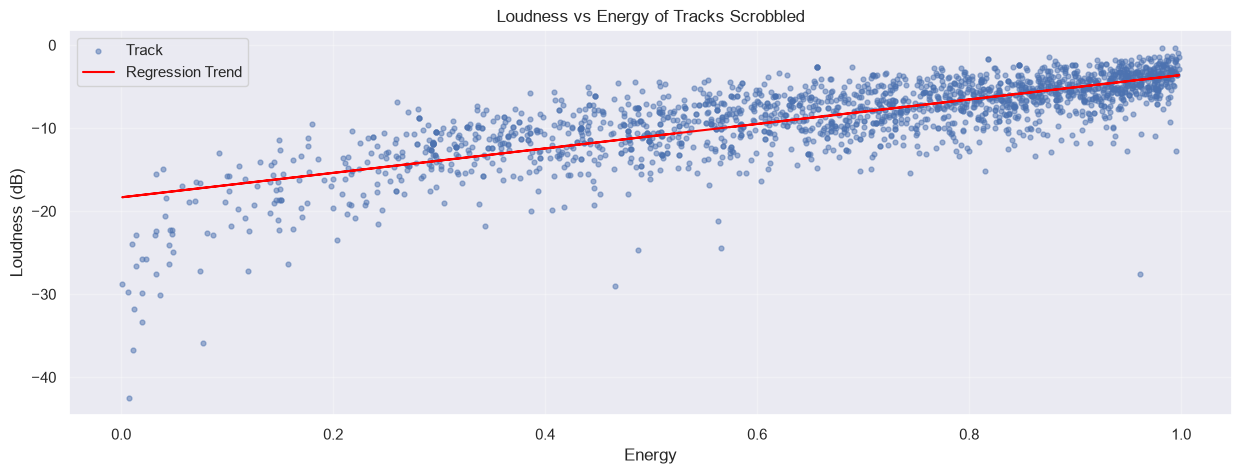

In [21]:
# one row per track so tracks I replayed a lot don't weight the line
tracks_feat = plays_feat.drop_duplicates(subset='song').dropna(subset=['energy', 'loudness'])

X = tracks_feat[['energy']]
y = tracks_feat['loudness']

# referenced Linear-Regression.ipynb:
# fit the estimator, then use predict() and score() for model evaluation
model = LinearRegression()
model.fit(X, y)

print(f"Slope (dB per 1.0 of energy):  {model.coef_[0]:.3f}")
print(f"Intercept:                     {model.intercept_:.1f}")
print(f"R-squared:                     {model.score(X, y):.4f}")
print(f"Tracks analysed:               {len(tracks_feat)}")

plt.figure(figsize=(15, 5))
plt.scatter(X['energy'], y, s=12, alpha=0.5, label='Track')
plt.plot(X['energy'], model.predict(X), color='red', label='Regression Trend')
plt.title('Loudness vs Energy of Tracks Scrobbled')
plt.xlabel('Energy')
plt.ylabel('Loudness (dB)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

There's a strong positive relationship between a track's energy and its loudness, with the baseline loudness starting at -18.3 dB and increasing by 14.73 dB for every 1.0 unit increase in energy

The straight line explains 60.29% of the variance in loudness, so it fits for more than half of the data

The scatter plot reveals a flattening effect as energy approaches 1.0, alongside a handful of extreme quiet outliers that sit far below the main data cluster.

Because the linear trend line didn't fit the curve at the high end of the spectrum of energy, a polynomial with a degree of 3 model was introduced to capture this 

Linear R-squared:      0.6029
Polynomial R-squared:  0.6584


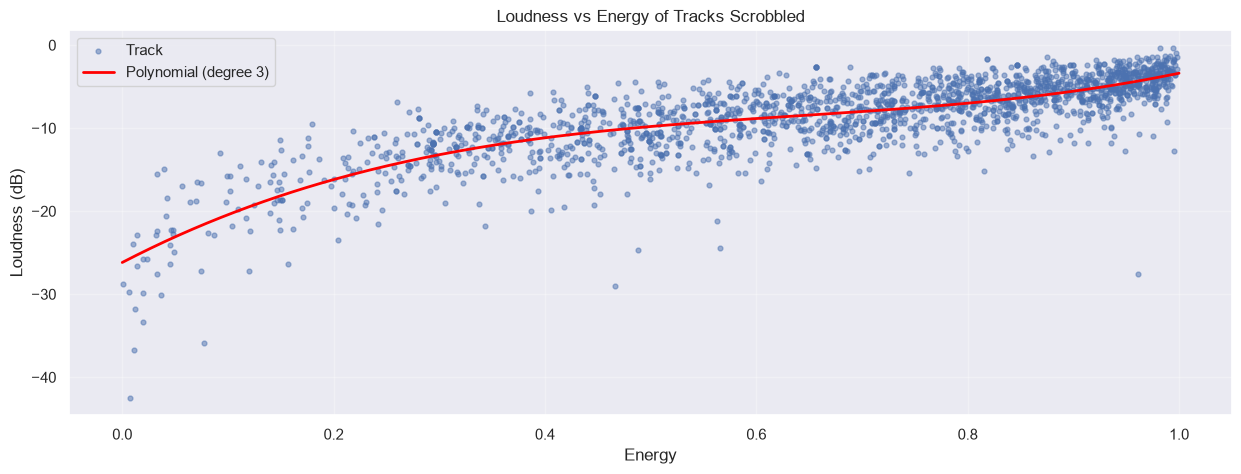

In [22]:
poly_model = make_pipeline(PolynomialFeatures(3), LinearRegression())
poly_model.fit(X, y)

print(f"Linear R-squared:      {model.score(X, y):.4f}")
print(f"Polynomial R-squared:  {poly_model.score(X, y):.4f}")

# evenly spaced energy values so the curve is drawn smoothly
x_grid = pd.DataFrame({'energy': np.linspace(0, 1, 300)})

plt.figure(figsize=(15, 5))
plt.scatter(X['energy'], y, s=12, alpha=0.5, label='Track')
plt.plot(x_grid['energy'], poly_model.predict(x_grid), color='red', linewidth=2, label='Polynomial (degree 3)')
plt.title('Loudness vs Energy of Tracks Scrobbled')
plt.xlabel('Energy')
plt.ylabel('Loudness (dB)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Transforming the data into a cubic polynomial yields a 5.5% increase in predictive power 

The curved red line accurately traces the plateauing loudness of songs with the maximum possible energy

The curve still fails to capture the low lodness outliers at the bottom left of the plot

**Question how many songs do I scrobble per day, and what drives it?**

Additional thought was given to the following: 

- Days with no listening at all are still real days, so they're filled in with 0
- Days end at midnight Dublin time
- Hours of daylight use Dublin's latitude (53.35 N) **

In [23]:
daily = plays.groupby('local_date').size().rename('scrobbles').to_frame()
# any missing days are filled with 0
daily = daily.reindex(fill_value=0)
daily.index.name = 'date'
print(f"Days analysed: {len(daily)}, days with zero scrobbles: {(daily['scrobbles'] == 0).sum()}")

# day of week cols
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
for i in range(7):
    daily[days[i]] = (daily.index.dayofweek == i).astype(float)

# irish public holidays (hard-coded so the notebook needs no extra package)
holidays = pd.to_datetime([
    '2025-01-01', '2025-02-03', '2025-03-17', '2025-04-21', '2025-05-05', '2025-06-02',
    '2025-08-04', '2025-10-27', '2025-12-25', '2025-12-26',
    '2026-01-01', '2026-02-02', '2026-03-17', '2026-04-06', '2026-05-04', '2026-06-01',
    '2026-08-03', '2026-10-26', '2026-12-25', '2026-12-26'])
daily['holiday'] = daily.index.isin(holidays).astype(float)

# hours of daylight for dublin's latitude
def hours_of_daylight(dates, axis=23.44, latitude=53.35):
    """Hours of daylight for a DatetimeIndex (Handbook formula, Dublin latitude)."""
    d = (dates - pd.Timestamp(2000, 12, 21)).days.to_numpy()
    m = 1.0 - np.tan(np.radians(latitude)) * np.tan(np.radians(axis) * np.cos(d * 2 * np.pi / 365.25))
    return 24.0 * np.degrees(np.arccos(1 - np.clip(m, 0, 2))) / 180.0

daily['daylight'] = hours_of_daylight(daily.index)
daily['annual'] = (daily.index - daily.index[0]).days / 365.25
daily.head()

Days analysed: 311, days with zero scrobbles: 0


,scrobbles,Mon,Tue,Wed,Thu,Fri,Sat,Sun,holiday,daylight,annual
date,,,,,,,,,,,
2025-11-18,183,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,8.162392,0.000000
2025-11-19,103,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,8.112555,0.002738
2025-11-20,135,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,8.063778,0.005476
2025-11-21,61,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,8.016092,0.008214
2025-11-22,122,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,7.969531,0.010951


Train R-squared:  0.262
Test R-squared:   -1.237
Test MAE:         42.1 scrobbles
Baseline MAE:     28.5 scrobbles
Mon         37.5
Tue         52.2
Wed         55.6
Thu         39.1
Fri         40.0
Sat         42.2
Sun         32.9
holiday    -10.9
daylight    -4.3
annual      90.4
prev7        0.6
dtype: float64


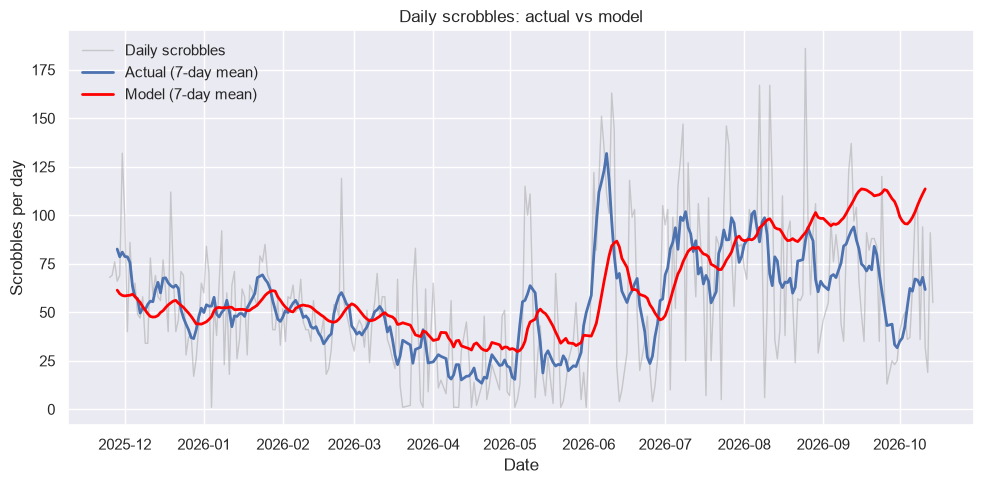

In [24]:
# fit on the first 80% of days (split by date, not randomly), then plot actual vs predicted (
daily['prev7'] = daily['scrobbles'].shift(1).rolling(7).mean()
data = daily.dropna().copy()

cols = days + ['holiday', 'daylight', 'annual', 'prev7']

# split by date, not randomly, so the model predicts days it hasn't seen (train_test_split from Hyperparameters-and-Model-Validation.ipynb would shuffle them)
# 0.8 = 80%
split = int(len(data) * 0.8)
train, test = data.iloc[:split], data.iloc[split:]


model_B = LinearRegression(fit_intercept=False).fit(train[cols], train['scrobbles'])
data['predicted'] = model_B.predict(data[cols])

baseline = train['scrobbles'].mean()

print(f"Train R-squared:  {model_B.score(train[cols], train['scrobbles']):.3f}")
print(f"Test R-squared:   {model_B.score(test[cols], test['scrobbles']):.3f}")
print(f"Test MAE:         {mean_absolute_error(test['scrobbles'], model_B.predict(test[cols])):.1f} scrobbles")
print(f"Baseline MAE:     {mean_absolute_error(test['scrobbles'], [baseline] * len(test)):.1f} scrobbles")
print(pd.Series(model_B.coef_, index=cols).round(1))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(data.index, data['scrobbles'], color="grey", alpha=0.35, lw=1, label='Daily scrobbles')
ax.plot(data.index, data['scrobbles'].rolling(7, center=True).mean(), lw=2, label='Actual (7-day mean)')
ax.plot(data.index, data['predicted'].rolling(7, center=True).mean(), color="red", lw=2, label='Model (7-day mean)')
ax.set(title='Daily scrobbles: actual vs model', xlabel='Date', ylabel='Scrobbles per day')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout()
plt.show()

## Logistic Regression 

### Research question

**Can the time of day help predict which of my ten most-listened-to artists I will listen to?**

This notebook uses Last.fm scrobbles to test whether listening time contains a useful signal about artist choice. 

It treats artist as a ten-class prediction problem

The analysis is limited to my ten most-scrobbled artists and uses time of day as the model feature


In [25]:
top_artists = plays['artist'].value_counts().head(10).index
subset = plays[plays['artist'].isin(top_artists)].copy()


print(subset['artist'].value_counts())
print(pd.crosstab(subset['tod'], subset['artist'], normalize='index').round(2))

artist
Arctic Monkeys           2230
Tame Impala              2042
Red Hot Chili Peppers    1559
Portishead               1199
Alice in Chains          1108
John Mayer                892
Ghost                     572
Morcheeba                 562
Pink Floyd                509
Massive Attack            500
Name: count, dtype: int64
artist     Alice in Chains  Arctic Monkeys  Ghost  John Mayer  Massive Attack  \
tod                                                                             
afternoon             0.10            0.19   0.07        0.07            0.05   
evening               0.09            0.23   0.02        0.10            0.04   
morning               0.12            0.11   0.11        0.02            0.08   
night                 0.06            0.27   0.00        0.14            0.02   

artist     Morcheeba  Pink Floyd  Portishead  Red Hot Chili Peppers  \
tod                                                                   
afternoon       0.03        0.04      

I encode `tod` as one-hot features and use the artist name as the target. The data is split into training and test sets, preserving each artist's share in both sets (`stratify=y`)

The pd.get_dummies() function is used to perform one-hot encoding on the `tod` column, converting it into binary indicator variables suitable for logistic regression. I followed [GeeksforGeeks'](https://www.geeksforgeeks.org/machine-learning/ml-one-hot-encoding/) tutorial for implementing this, see [also](https://www.geeksforgeeks.org/pandas/python-pandas-get_dummies-method/) 

I compare the model's test accuracy with a baseline that predicts the most common artist in the data. The classification report also shows precision, recall, and F1-score for each artist, which helps reveal whether accuracy hides poor results for less frequent artists

In [26]:
# get dummies referenced from https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/03.10-Working-With-Strings.ipynb
X = pd.get_dummies(subset['tod']).astype(int)
y = subset['artist']

# followed Hyperparameters-and-Model-Validation.ipynb from example PythonDataScienceHanbook repo in class
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# logistic regression is used here for this Last.fm multiclass prediction
log_regress = LogisticRegression(max_iter=1000)
log_regress.fit(X_train, y_train)
y_pred = log_regress.predict(X_test)

baseline = y_train.value_counts().idxmax()
print('Baseline accuracy:', accuracy_score(y_test, [baseline] * len(y_test)))
print('Model accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Baseline accuracy: 0.19955257270693513
Model accuracy: 0.23355704697986576
                       precision    recall  f1-score   support

      Alice in Chains       0.00      0.00      0.00       222
       Arctic Monkeys       0.23      0.57      0.33       446
                Ghost       0.00      0.00      0.00       114
           John Mayer       0.00      0.00      0.00       178
       Massive Attack       0.00      0.00      0.00       100
            Morcheeba       0.00      0.00      0.00       112
           Pink Floyd       0.00      0.00      0.00       102
           Portishead       0.00      0.00      0.00       240
Red Hot Chili Peppers       0.00      0.00      0.00       312
          Tame Impala       0.23      0.65      0.34       409

             accuracy                           0.23      2235
            macro avg       0.05      0.12      0.07      2235
         weighted avg       0.09      0.23      0.13      2235



### Multiclass result

The model reaches **23.4% test accuracy**, compared with **20.0%** for the most-common-artist baseline. That is a gain of about **3.4 percentage points**, so time of day adds only a small amount of predictive value overall.

The per-artist report gives a more important warning: the model has non-zero precision and recall for only Arctic Monkeys and Tame Impala, and scores zero for the other eight artists. The overall accuracy therefore overstates how useful the model is across the full set of artists.

**Takeaway:** time of day alone does not reliably identify which of the ten artists will be played. The probability table below shows the model's estimated distribution for each time category, rather than a dependable recommendation.

           Alice in Chains  Arctic Monkeys  Ghost  John Mayer  Massive Attack  \
morning               0.12            0.11   0.10        0.02            0.07   
afternoon             0.10            0.19   0.07        0.07            0.05   
evening               0.09            0.23   0.02        0.10            0.04   
night                 0.06            0.27   0.01        0.14            0.02   

           Morcheeba  Pink Floyd  Portishead  Red Hot Chili Peppers  \
morning         0.05        0.01        0.09                   0.11   
afternoon       0.03        0.04        0.08                   0.16   
evening         0.06        0.06        0.14                   0.14   
night           0.10        0.09        0.10                   0.04   

           Tame Impala  
morning           0.31  
afternoon         0.21  
evening           0.13  
night             0.17  


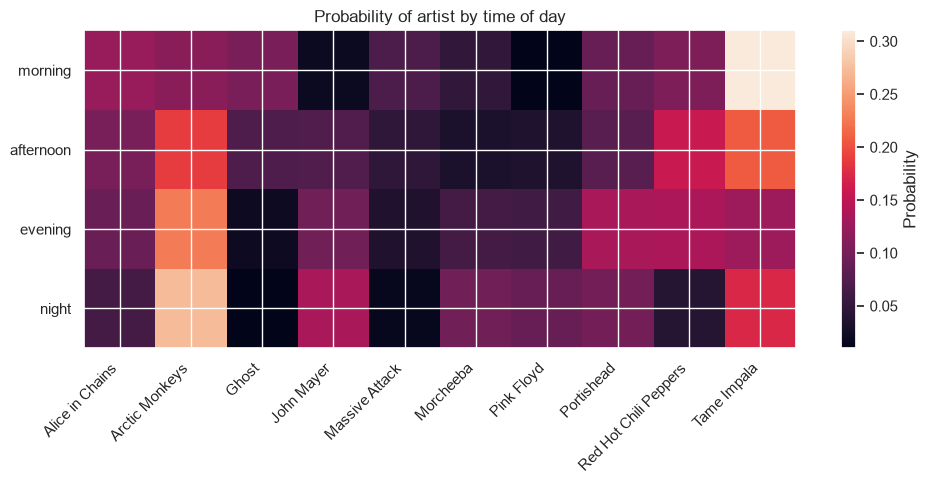

In [27]:
buckets = pd.DataFrame(np.eye(len(X.columns), dtype=int), columns=X.columns, index=X.columns)
probs = pd.DataFrame(log_regress.predict_proba(buckets), columns=log_regress.classes_, index=buckets.index)
probs = probs.reindex(['morning', 'afternoon', 'evening', 'night'])
print(probs.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(probs.values, aspect='auto')
ax.set_xticks(range(len(probs.columns)))
ax.set_xticklabels(probs.columns, rotation=45, ha='right')
ax.set_yticks(range(len(probs.index)))
ax.set_yticklabels(probs.index)
fig.colorbar(im, label='Probability')
ax.set_title('Probability of artist by time of day')
plt.tight_layout()
plt.show()

## Result

For the ten-class question, the model improves on the majority-artist baseline by only about 3.4 percentage points and fails to identify eight artists in the test set. Time of day alone is therefore a weak predictor of the specific artist.

**Answer to the research question:** listening time contains some signal, especially for a few artists, but it is not enough on its own to reliably predict artist choice. Day of week, listening history, or additional context could be tested as further features

## K-Means Clustering

### Research question

**Do the tracks I have listened to group into clusters based on their Spotify audio features, and does the grouping match the time of day I listened to them?**

## Choosing Cluster Amount
The inertia and silhouette table above was used to pick the number of clusters. Silhouette scores peak at k=2 and then settles between k=3 through k=8

A two-cluster solution has the highest score, but it only splits the data into loud versus quiet

Four clusters were chosen because they keep a reasonable silhouette (0.203) while producing groups that map onto recognisable listening categories

Each of the four clusters is separated by at least one distinct audio feature

     inertia  silhouette
k                       
2  10410.411       0.269
3   8910.139       0.191
4   7903.484       0.203
5   7018.879       0.213
6   6237.531       0.216
7   5775.445       0.216
8   5408.075       0.218


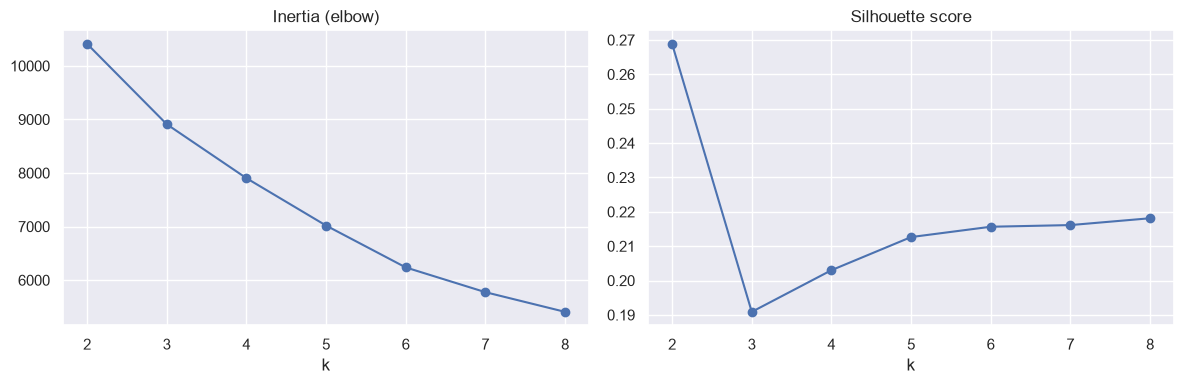

In [28]:
# loudness is dropped because energy is partly derived from it
kmeans_features = ['danceability', 'energy', 'acousticness', 'instrumentalness',
               'liveness', 'valence', 'speechiness']

# one row per unique track
tracks = (scrobbles.drop_duplicates(['clean_artist', 'clean_track'])
          .dropna(subset=kmeans_features).copy())
X_kmeans = StandardScaler().fit_transform(tracks[kmeans_features])

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_kmeans)
    rows.append({'k': k, 'inertia': km.inertia_,
                 'silhouette': silhouette_score(X_kmeans, km.labels_)})
k_scores = pd.DataFrame(rows).set_index('k')
print(k_scores.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
k_scores['inertia'].plot(marker='o', ax=ax[0], title='Inertia (elbow)')
k_scores['silhouette'].plot(marker='o', ax=ax[1], title='Silhouette score')
plt.tight_layout()
plt.show()

cluster
0    818
1     34
2    347
3    639
Name: count, dtype: int64
         danceability  energy  acousticness  instrumentalness  liveness  \
cluster                                                                   
0                0.37    0.80          0.05              0.20      0.22   
1                0.47    0.68          0.26              0.13      0.22   
2                0.46    0.32          0.62              0.33      0.18   
3                0.60    0.72          0.11              0.20      0.19   

         valence  speechiness  
cluster                        
0           0.32         0.07  
1           0.38         0.51  
2           0.26         0.04  
3           0.64         0.06  


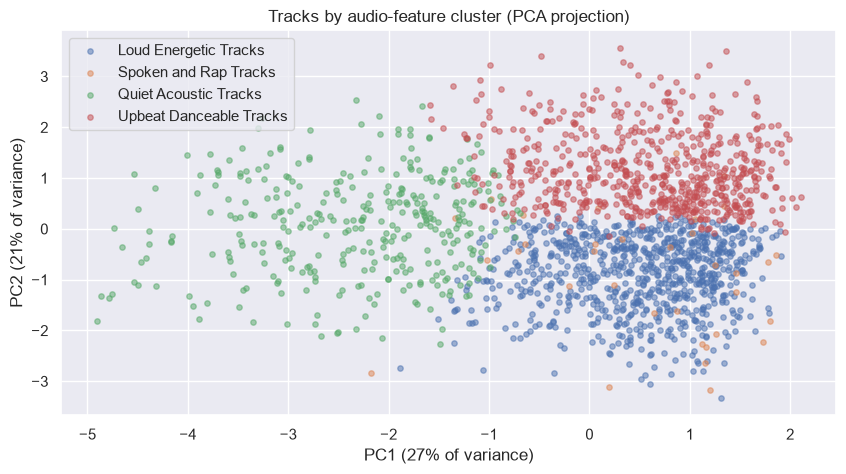

In [29]:
no_clusters = 4   

kmeans = KMeans(n_clusters=no_clusters, random_state=42, n_init=10)
tracks['cluster'] = kmeans.fit_predict(X_kmeans)

print(tracks['cluster'].value_counts().sort_index())
print(tracks.groupby('cluster')[kmeans_features].mean().round(2))

cluster_labels = {
    0: "Loud Energetic Tracks",
    1: "Spoken and Rap Tracks",
    2: "Quiet Acoustic Tracks",
    3: "Upbeat Danceable Tracks"
}

pca = PCA(n_components=2)
coords = pca.fit_transform(X_kmeans)

plt.figure(figsize=(10, 5))
for cluster in range(no_clusters):
    mask = tracks['cluster'] == cluster
    plt.scatter(coords[mask, 0], coords[mask, 1],
                label=cluster_labels[cluster], alpha=0.5, s=15)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)')
plt.title('Tracks by audio-feature cluster (PCA projection)')
plt.legend()
plt.show()

### Cluster 0 - Loud Energetic Tracks

Cluster 0 has the highest energy (0.80) and the lowest acousticness (0.05). Valence is on the lower side (0.32)

These are the heavier tracks, rock, metal and high-intensity electronic music. The loud, non-acoustic and somewhat darker profile matches that description

### Cluster 1 - Spoken and Rap Tracks

Cluster 1 is separated by speechiness, which sits at 0.51 compared to around 0.04 to 0.07 for the other three clusters

Speechiness at that level means the vocal content is spoken or rapped rather than sung (Rap tracks, spoken word and anything with a dominant vocal delivery)

### Cluster 2 - Quiet Acoustic Tracks

Cluster 2 has the highest acousticness (0.62) and the lowest energy (0.32). Valence is also low at 0.26

This is the opposite end of the spectrum from cluster 0. Quiet, acoustic, instrumental-leaning tracks. Ambient, folk and acoustic singer-songwriter tracks would cluster here

Combined with the time-of-day table below, this cluster is also the one most likely to show up at night

### Cluster 3 - Upbeat Danceable Tracks

Cluster 3 has the highest valence (0.64) of any cluster, with energy at 0.72 and acousticness low at 0.11

These are the tracks that sound bright and happy (Pop, upbeat rock and dance tracks)

14,629 plays carry a cluster
cluster       0    1     2     3
tod                             
morning    51.0  1.5  12.9  34.6
afternoon  43.4  0.7  16.2  39.7
evening    30.6  0.4  23.1  45.8
night      22.7  1.0  24.9  51.4


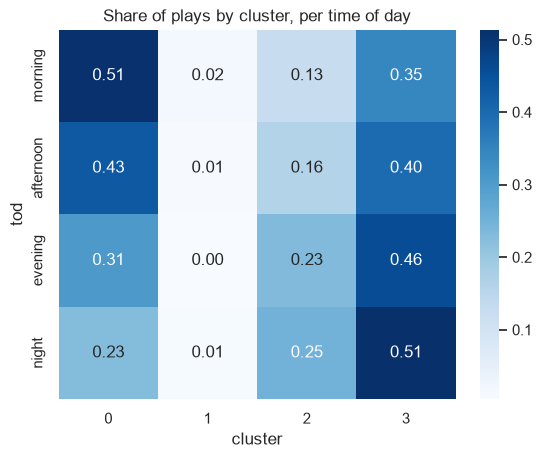

cluster
0    0.391
1    0.008
2    0.186
3    0.415
Name: proportion, dtype: float64
cluster
0    0.174
1    0.000
2    0.226
3    0.171
Name: is_loved, dtype: float64


In [30]:
plays_c = plays.merge(tracks[['clean_artist', 'clean_track', 'cluster']],
                      on=['clean_artist', 'clean_track'], how='inner')
print(f"{len(plays_c):,} plays carry a cluster")

# share of each cluster within each time of day
share = (pd.crosstab(plays_c['tod'], plays_c['cluster'], normalize='index')
         .reindex(['morning', 'afternoon', 'evening', 'night']))
print((share * 100).round(1))

sns.heatmap(share, annot=True, fmt='.2f', cmap='Blues')
plt.title('Share of plays by cluster, per time of day')
plt.show()

print(plays_c['cluster'].value_counts(normalize=True).sort_index().round(3))
print(plays_c.groupby('cluster')['is_loved'].mean().round(3))   # loved rate per cluster

### What the clusters show

The clusters are defined by audio features, not by artist, so a single artist can span multiple clusters. A band with both acoustic and heavy tracks will split across clusters 0 and 2

The cluster profile means above show that the four groups are genuinely separated in feature space rather than being arbitrary divisions of a continuous spread

Whether those groups line up with the time of day I listened is the question the next section tests

## Decision Tree

### Research question

**Can the audio features of a track predict which time of day I listened to it?**

The 9 features come from the Spotify audio feature dataset

In [31]:
audio_features = ['acousticness', 'danceability', 'energy', 'instrumentalness',
         'liveness', 'loudness', 'speechiness', 'tempo', 'valence']

First, I need to combine all of the raw scrobbles with their features from the merged dataset, has one row per unique track. The result is 14,629 scrobbled tracks that have audio features

The target `tod` has four values: night (22:00 to 04:59), morning (05:00 to 11:59), afternoon (12:00 to 16:59) and evening (17:00 to 21:59). Afternoon has 5,917 plays, evening 5,734, morning 2,573 and night only 405, so the classes are imbalanced

In [32]:
plays['clean_track'] = clean_text(plays['song'])
plays['clean_artist'] = clean_artist(plays['artist'])

lookup = scrobbles[['clean_artist', 'clean_track'] + audio_features].drop_duplicates(
    subset=['clean_artist', 'clean_track'])

df = plays[['timestamp', 'hour', 'tod', 'clean_artist', 'clean_track']].merge(
    lookup, on=['clean_artist', 'clean_track'], how='inner')
df = df.sort_values('timestamp').reset_index(drop=True)

print(len(plays), 'plays,', len(df), 'with audio features')
print(df['tod'].value_counts())

17999 plays, 14629 with audio features
tod
afternoon    5917
evening      5734
morning      2573
night         405
Name: count, dtype: int64


I sorted plays by time and used the first 75% (10,971 plays) for training and the last 25% (3,658 plays) for testing

A time-ordered split avoids testing on plays that sit between training plays, and mimics an app predicting future listening from past listening

The baseline is the accuracy of always guessing the most common class in the test set. That is evening, with an accuracy of **0.406**. Any model has to beat this to be worth using

In [33]:
X = df[audio_features]
y = df['tod']
cut = int(len(df) * 0.75)
Xtrain, Xtest = X.iloc[:cut], X.iloc[cut:]
ytrain, ytest = y.iloc[:cut], y.iloc[cut:]

baseline = ytest.value_counts(normalize=True).max()
print('Baseline (biggest class):', round(baseline, 3))

Baseline (biggest class): 0.406


Next, I trained trees at several depths and compared training and test accuracy

Training accuracy rises with depth, from 0.476 at depth 2 to 0.601 with no limit. Test accuracy goes the other way, from 0.468 at depth 2 down to 0.453 with no limit

That gap is overfitting: the deeper trees learn patterns in the training period that do not carry over to the test period

In [34]:
for depth in [2, 3, 4, 5, 8, None]:
    t = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(Xtrain, ytrain)
    print('max_depth =', depth,
          ' train / test:', round(t.score(Xtrain, ytrain), 3),
          '/', round(t.score(Xtest, ytest), 3))

max_depth = 2  train / test: 0.476 / 0.468
max_depth = 3  train / test: 0.487 / 0.464
max_depth = 4  train / test: 0.492 / 0.462
max_depth = 5  train / test: 0.497 / 0.464
max_depth = 8  train / test: 0.537 / 0.455
max_depth = None  train / test: 0.601 / 0.453


              precision    recall  f1-score   support

   afternoon       0.43      0.62      0.51      1438
     evening       0.51      0.54      0.52      1484
     morning       0.24      0.01      0.02       634
       night       0.00      0.00      0.00       102

    accuracy                           0.46      3658
   macro avg       0.30      0.29      0.26      3658
weighted avg       0.42      0.46      0.42      3658



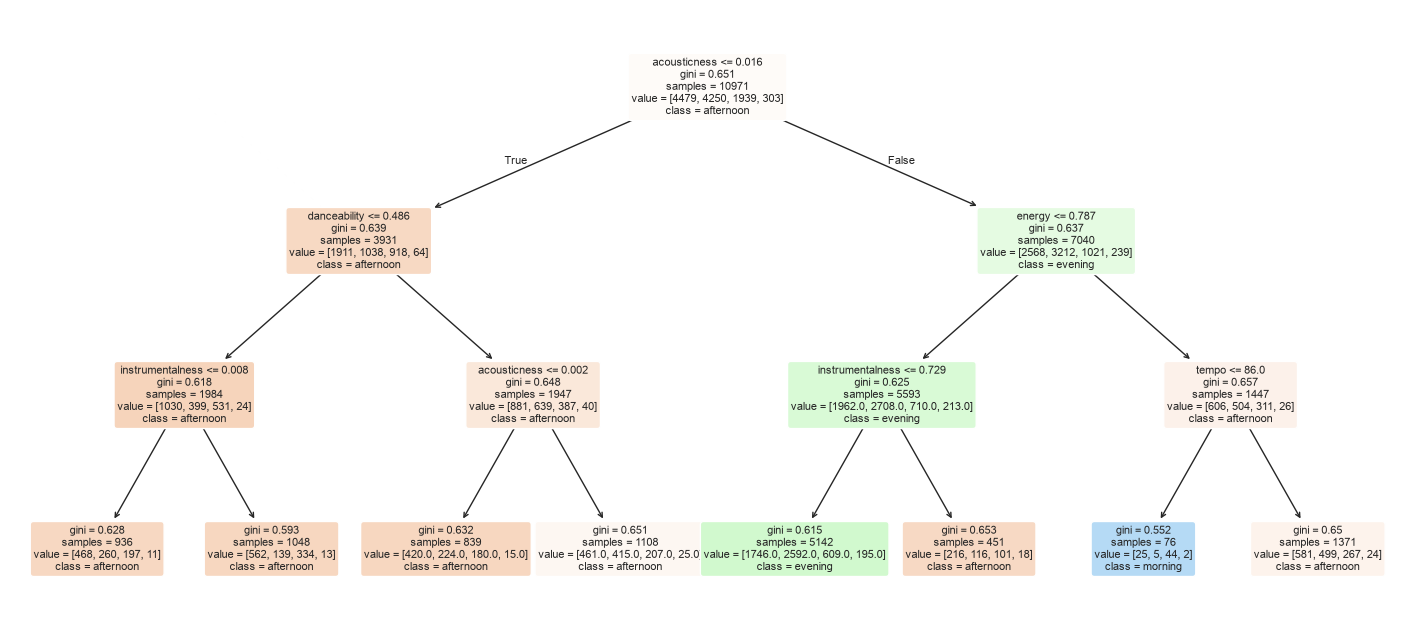

|--- acousticness <= 0.02
|   |--- danceability <= 0.49
|   |   |--- instrumentalness <= 0.01
|   |   |   |--- class: afternoon
|   |   |--- instrumentalness >  0.01
|   |   |   |--- class: afternoon
|   |--- danceability >  0.49
|   |   |--- acousticness <= 0.00
|   |   |   |--- class: afternoon
|   |   |--- acousticness >  0.00
|   |   |   |--- class: afternoon
|--- acousticness >  0.02
|   |--- energy <= 0.79
|   |   |--- instrumentalness <= 0.73
|   |   |   |--- class: evening
|   |   |--- instrumentalness >  0.73
|   |   |   |--- class: afternoon
|   |--- energy >  0.79
|   |   |--- tempo <= 86.00
|   |   |   |--- class: morning
|   |   |--- tempo >  86.00
|   |   |   |--- class: afternoon

acousticness        0.545702
instrumentalness    0.186687
energy              0.122304
danceability        0.085062
tempo               0.060244
liveness            0.000000
loudness            0.000000
speechiness         0.000000
valence             0.000000
dtype: float64


In [35]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xtrain, ytrain)
ypred = tree.predict(Xtest)
print(classification_report(ytest, ypred, zero_division=0))

plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=audio_features, class_names=list(tree.classes_),
          filled=True, rounded=True, fontsize=8)
plt.show()

print(export_text(tree, feature_names=audio_features))
print(pd.Series(tree.feature_importances_, index=audio_features).sort_values(ascending=False))

### Results

Afternoon and evening are predicted quite frequently (recall 0.62 and 0.54), but morning recall is 0.01 and night recall is 0.00. The tree almost never predicts morning or night, so really it is choosing between afternoon and evening

Acousticness is the most important feature (about 0.55), followed by instrumentalness (0.19), energy (0.12), danceability (0.09) and tempo (0.06)

The other four features were unused. The first split is on acousticness, where low-acousticness tracks are predicted as afternoon, and in the more acoustic branch, tracks with lower energy are predicted as evening. 

The only rule that predicts morning is high energy (above 0.79) with a tempo of 86 or below, which covers few plays

## Conclusion

Audio features carry a little information about when I listen, acousticness being the dominant feature that separates my afternoon plays from my evening plays, but the signal is weak. 

The tree beats the always guess evening baseline by about 5 points and does not identify morning or night at all

Limitations: 3,370 plays were dropped for missing audio features, the night class is small (405 plays), the time-ordered test set covers only the most recent period of my listening

## Sources

- Medina, C. (n.d.) 'Using the Last.fm API to extract data and analyzing it with Python - Part 1' [online] Hemisferios, Medium, Available at: https://medium.com/hemisferios/using-the-last-fm-api-to-extract-data-and-analyzing-it-with-python-part-1-ffe96f812455 [Accessed: 6th Oct 2026]
- Last.fm (n.d.) 'Last.fm API' [online] Last.fm, Available at: https://www.last.fm/api [Accessed: 6th Oct 2026]
- Last.fm API Docs (n.d.) 'user.getLovedTracks' [online] Unofficial Last.fm API documentation, Available at: https://lastfm-docs.github.io/api-docs/user/getLovedTracks/#examples [Accessed: 6th Oct 2026]
- GD-Studio (n.d.) 'embeat_45m_spotify_tracks' [online] Hugging Face, Available at: https://huggingface.co/datasets/GD-Studio/embeat_45m_spotify_tracks [Accessed: 17th Oct 2026]
- Spotify (n.d.) 'Get Several Tracks' Audio Features' [online] Spotify for Developers, Available at: https://developer.spotify.com/console/get-audio-features-several-tracks [Accessed: 17th Oct 2026]
- Hugging Face (n.d.) 'Stream' [online] Hugging Face Hub documentation, Available at: https://huggingface.co/docs/hub/en/datasets-streaming [Accessed: 17th Oct 2026]
- VanderPlas, J. (2016) 'In Depth: Linear Regression' [online] Python Data Science Handbook, Available at: https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.06-Linear-Regression.ipynb [Accessed: 17th Oct 2026]
- VanderPlas, J. (2016) 'Hyperparameters and Model Validation' [online] Python Data Science Handbook, Available at: https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.03-Hyperparameters-and-Model-Validation.ipynb [Accessed: 17th Oct 2026]
- scikit-learn (n.d.) 'sklearn.preprocessing.PolynomialFeatures' [online] scikit-learn documentation, Available at: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html [Accessed: 17th Oct 2026]
- GeeksforGeeks (n.d.) 'One Hot Encoding in Machine Learning' [online] GeeksforGeeks, Available at: https://www.geeksforgeeks.org/machine-learning/ml-one-hot-encoding/ [Accessed: 13th Oct 2026]
- GeeksforGeeks (n.d.) 'Python | Pandas get_dummies() method' [online] GeeksforGeeks, Available at: https://www.geeksforgeeks.org/pandas/python-pandas-get_dummies-method/ [Accessed: 13th Oct 2026]
- scikit-learn (n.d.) 'sklearn.model_selection.train_test_split' [online] scikit-learn documentation, Available at: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html [Accessed: 13th Oct 2026]
- VanderPlas, J. (2016) 'Vectorized String Operations' [online] Python Data Science Handbook, Available at: https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/03.10-Working-With-Strings.ipynb [Accessed: 13th Oct 2026]
